## Tools in LangGraph 

In [65]:

from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langchain_core.tools import tool
from langchain_core.messages import AIMessage, HumanMessage, ToolMessage, SystemMessage
import os

load_dotenv()

if os.environ['OPENAI_API_KEY']:
    print("Openai key is set")
else:
    raise ValueError("openAi key is not set")


llm_openai = ChatOpenAI(model='gpt-5-mini',temperature=0)



Openai key is set


## Wikipedia Tool

In [66]:
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper

@tool
def wiki_search(query:str)-> str:
    """This tool allows you to search Wikipedia for information on a given topic."""
    wiki_query = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())
    return wiki_query.invoke(query)


## DuckDuckGo Search tool

In [67]:
from langchain_community.tools import DuckDuckGoSearchRun

@tool
def search_duckduckgo(query: str) -> str:

    """This tool searches the latest news on DuckDuckGo for the given query and returns the results."""
    duck_search = DuckDuckGoSearchRun()
    return duck_search.invoke(query)

## Custome Tool

In [68]:


@tool
def personal_info(query:str)-> str:
    """Get personal information about alice, bob....."""
    info={
        "Alice": "Alice is a software engineer with 5 years of experience in AI.",
        "Bob": "Bob is a data scientist who loves working with large datasets.",
        "Charlie": "Charlie is a product manager with a background in tech startups."
    }
    return info.get(query,'no info found')


## Bind the tool 

In [69]:
tools =[personal_info,search_duckduckgo,wiki_search]

llm_openai_withtools=llm_openai.bind_tools(tools)


In [70]:
from typing import TypedDict, List

class graph_schema(TypedDict):
    message:List


In [71]:
from langchain_core.prompts import ChatPromptTemplate

def llm_node(state:graph_schema)->graph_schema:
    message = state['message']
    prompt = ChatPromptTemplate.from_messages(
        [
            ("system", "You are a helpful assistant that can use tools to answer questions."),
            ("human", "{input}")
        ]
    )
    chain = prompt | llm_openai_withtools

    response = chain.invoke({'input': message})

    state ["message"]= message + [response]
    return state

In [72]:

def tool_node (state:graph_schema)-> graph_schema:
    message = state['message']
    tools_by_name = { tool.name:tool for tool in tools }
    tool_results=[]

    for tool_call in message[-1].tool_calls:
        tool = tools_by_name[tool_call["name"]]
        observation = tool.invoke(tool_call["args"])

        tool_results.append(ToolMessage(content=observation, tool_call_id=tool_call["id"]))

    state['message'] = message + tool_results

    return state

In [73]:
def if_tool_call(state: graph_schema) -> str:

    last_message = state['message'][-1]

    if last_message.tool_calls:
        return "tool_node"
    else:
        return "end"

In [74]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)

# Add nodes to the graph
graph.add_node("llm_node", llm_node)
graph.add_node("tool_node", tool_node)

# Add edges between nodes
graph.add_edge(START, "llm_node")
graph.add_conditional_edges("llm_node", if_tool_call,{"tool_node": "tool_node", "end": END})
graph.add_edge("tool_node", "llm_node")
graph.add_edge("llm_node", END)


react_graph = graph.compile()



react_graph.invoke({"message": [HumanMessage(content="What is the latest news on AI?")]})

{'message': [HumanMessage(content='What is the latest news on AI?', additional_kwargs={}, response_metadata={}),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 93, 'prompt_tokens': 227, 'total_tokens': 320, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-EdvpK3f0X3l8DnbUXhm6ZS6zYdj9h', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a18233-ae66-709d-8074-859e93f52186-0', tool_calls=[{'name': 'search_duckduckgo', 'args': {'query': 'latest news on AI'}, 'id': 'call_8e8rOj0cqJolkyPJlGR23qHY', 'type': 'tool_call'}], invalid

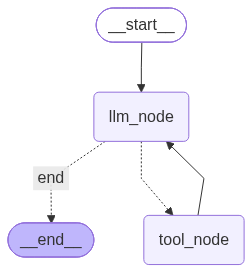

In [75]:
from IPython.display import Image, display

# You could see the errors with the below command
Image(react_graph.get_graph().draw_mermaid_png())